In [1]:
import sys
print(sys.executable)
print(sys.version)

C:\Users\Giahu\AppData\Local\Programs\Python\Python311\python.exe
3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]


In [5]:
import sys
!{sys.executable} -m pip install matplotlib


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: C:\Users\Giahu\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [6]:
import os
import numpy as np
from tensorflow.keras.datasets import mnist
# Load dataset (auto-downloads first time)
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# Create folder in current working directory
save_dir = "mnist_data"
os.makedirs(save_dir, exist_ok=True)
# Save arrays as .npy files
np.save(os.path.join(save_dir, "X_train.npy"), X_train)
np.save(os.path.join(save_dir, "y_train.npy"), y_train)
np.save(os.path.join(save_dir, "X_test.npy"), X_test)
np.save(os.path.join(save_dir, "y_test.npy"), y_test)
print("MNIST dataset saved in folder:", save_dir)

MNIST dataset saved in folder: mnist_data


In [7]:
# Import libraries
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# Normalize pixel values (0–255 → 0–1)
X_train = X_train / 255.0
X_test = X_test / 255.0
# Reshape for CNN (add channel dimension)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)
# Build CNN model
model = models.Sequential()
model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))
# Compile model 
model.compile(
 optimizer='adam',
 loss='sparse_categorical_crossentropy',
 metrics=['accuracy']
)
# Train model
model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)
# Evaluate model
test_loss, test_acc = model.evaluate(X_test, y_test)
print("\nTest Accuracy:", test_acc)
# Predict one sample
import numpy as np
sample = X_test[0].reshape(1, 28, 28, 1)
prediction = model.predict(sample)
print("Predicted Digit:", np.argmax(prediction))


C:\Users\Giahu\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 37s 40ms/step - accuracy: 0.9495 - loss: 0.1689 - val_accuracy: 0.9842 - val_loss: 0.0565
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 37s 44ms/step - accuracy: 0.9857 - loss: 0.0478 - val_accuracy: 0.9882 - val_loss: 0.0399
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 43ms/step - accuracy: 0.9898 - loss: 0.0326 - val_accuracy: 0.9887 - val_loss: 0.0381
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 29s 34ms/step - accuracy: 0.9923 - loss: 0.0242 - val_accuracy: 0.9892 - val_loss: 0.0414
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 42s 36ms/step - accuracy: 0.9935 - loss: 0.0194 - val_accuracy: 0.9913 - val_loss: 0.0351
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9918 - loss: 0.0257

Test Accuracy: 0.9918000102043152
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
Predicted Digit: 7


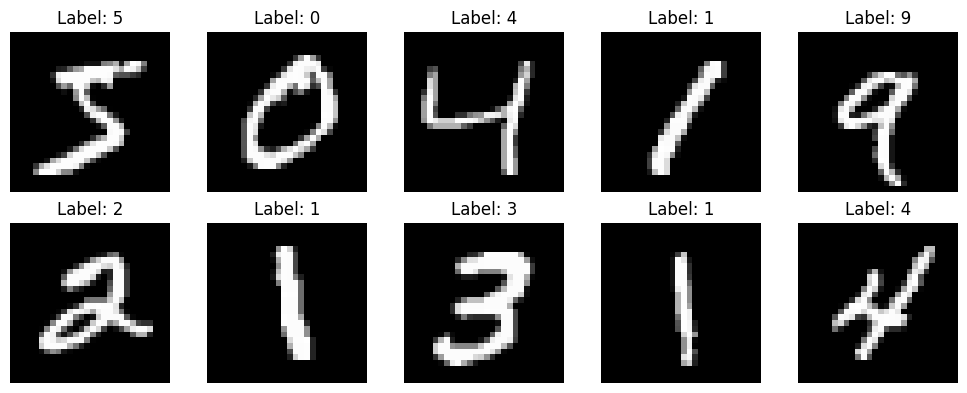

In [8]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
# Load dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# Display first 10 images
plt.figure(figsize=(10, 4))
for i in range(10):
 plt.subplot(2, 5, i + 1)
 plt.imshow(X_train[i], cmap='gray')
 plt.title(f"Label: {y_train[i]}")
 plt.axis('off')
plt.tight_layout()
plt.show()


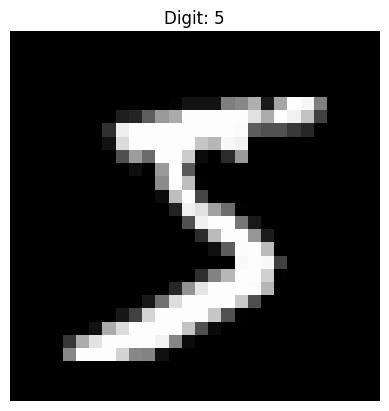

In [9]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
(X_train, y_train), _ = mnist.load_data()
plt.imshow(X_train[0], cmap='gray')
plt.title(f"Digit: {y_train[0]}")
plt.axis('off')
plt.show()

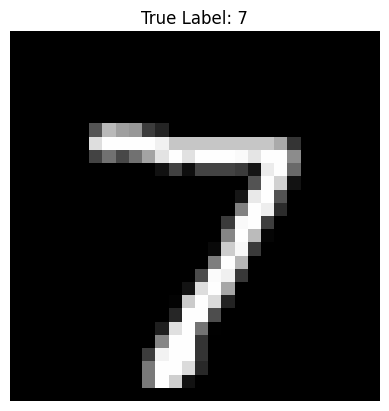

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
Predicted Digit: 7


In [10]:
import numpy as np
import matplotlib.pyplot as plt
# pick a test image
img = X_test[0]
# display image
plt.imshow(img.reshape(28, 28), cmap='gray')
plt.title(f"True Label: {y_test[0]}")
plt.axis('off')
plt.show()
# prediction
prediction = model.predict(img.reshape(1, 28, 28, 1))
print("Predicted Digit:", np.argmax(prediction))

In [11]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report
# Load dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# Normalize
X_train = X_train / 255.0
X_test = X_test / 255.0
# Reshape for CNN
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)
# Build CNN model
model = models.Sequential([
 layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
 layers.MaxPooling2D((2,2)),
 layers.Conv2D(64, (3,3), activation='relu'),
 layers.MaxPooling2D((2,2))
 layers.Flatten(),
 layers.Dense(128, activation='relu'),
 layers.Dense(10, activation='softmax')
])
# Compile model
model.compile(optimizer='adam',
 loss='sparse_categorical_crossentropy',
 metrics=['accuracy'])
# Train model
model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)
# Predict test data
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
# Plot confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - CNN on MNIST")
plt.show()
# Classification report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

SyntaxError: invalid syntax. Perhaps you forgot a comma? (521553089.py, line 21)